In [1]:
import numpy as np
from scipy.signal import convolve2d
from PIL import Image
import matplotlib.pyplot as plt
import cv2

In [2]:
# convolution with 4 for loops
def conv_4(x, k):
    H, W = x.shape
    Kh, Kw = k.shape
    output = np.zeros((H, W), dtype=float)
    for i in range(H):
        for j in range(W):
            total = 0.0
            for ki in range(Kh):
                for kj in range(Kw):
                    r = i + (ki - Kh // 2)
                    c = j + (kj - Kw // 2)
                    if 0 <= r < H and 0 <= c < W:
                        total += x[r, c] * k[ki, kj]
            output[i, j] = total   
    return output

# convolution with 2 for loops
def conv_2(x, k):
    H, W = x.shape
    Kh, Kw = k.shape
    padded = np.pad(x, ((Kh // 2, Kh // 2), (Kw // 2, Kw // 2)), mode='constant', constant_values=0)
    output = np.zeros((H, W), dtype=float)
    
    for i in range(H):
        for j in range(W):
            output[i, j] = np.sum(padded[i : i + Kh, j : j + Kw] * k)
    return output

# convolution with scipy.signal.convolve2d
def conv_s(x, k):
    return convolve2d(x, k[::-1, ::-1], mode='same', boundary='fill', fillvalue=0)

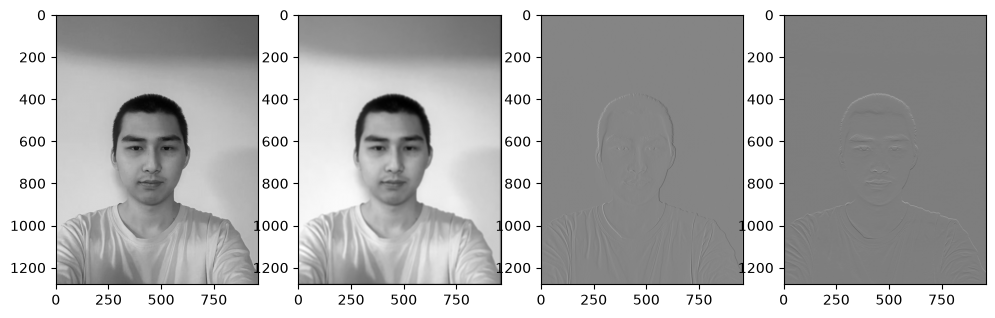

In [3]:
x = np.array(Image.open("./images/portrait.jpg").convert('L'), dtype=float)
Dx = 0.5 * np.array([[1.0, 0.0, -1.0]])
Dy = 0.5 * np.array([[1.0],[0.0],[-1.0]])
plt.figure(figsize=(12, 5))
plt.subplot(1, 4, 1)
plt.imshow(x, cmap='gray')
plt.subplot(1, 4, 2)
plt.imshow(conv_s(x, np.ones((9, 9), dtype=float) / 81.0), cmap='gray')
plt.subplot(1, 4, 3)
plt.imshow(conv_s(x, Dx), cmap='gray')
plt.subplot(1, 4, 4)
plt.imshow(conv_s(x, Dy), cmap='gray')

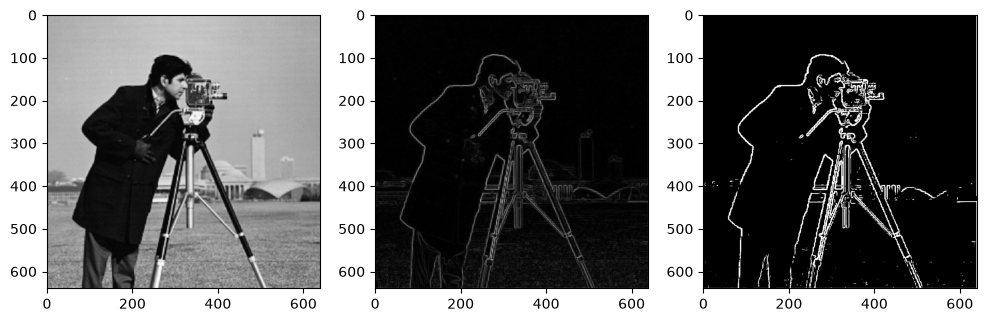

In [4]:
x = np.array(Image.open("./images/cameraman.jpg").convert('L'), dtype=float)
dx = conv_s(x, Dx)
dy = conv_s(x, Dy)
magnit = np.sqrt(dx**2 + dy**2)
plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(x, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(magnit, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow((magnit >= 24).astype(np.uint8) * 255, cmap='gray')

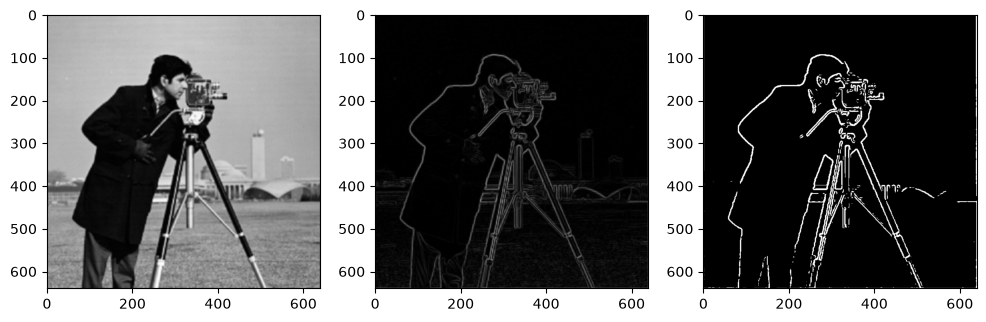

In [5]:
k1 = cv2.getGaussianKernel(ksize=5, sigma=1)
k2 = k1 @ k1.T

sx = conv_s(x, k2)
dx = conv_s(sx, Dx)
dy = conv_s(sx, Dy)
magnit = np.sqrt(dx**2 + dy**2)

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(sx, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(magnit, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow((magnit >= 24).astype(np.uint8) * 255, cmap='gray')

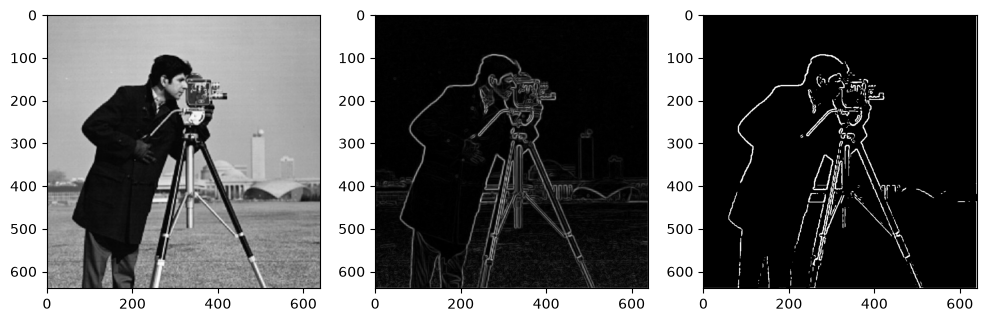

In [6]:
DoG_x = conv_s(k2, Dx)
DoG_y = conv_s(k2, Dy)
dx = conv_s(x, DoG_x)
dy = conv_s(x, DoG_y)
magnit = np.sqrt(dx**2 + dy**2)

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(x, cmap='gray')
plt.subplot(1, 3, 2)
plt.imshow(magnit, cmap='gray')
plt.subplot(1, 3, 3)
plt.imshow((magnit >= 24).astype(np.uint8) * 255, cmap='gray')

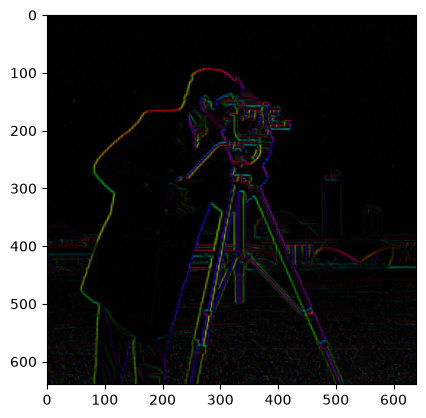

In [7]:
dx = cv2.Sobel(x, cv2.CV_64F, 1, 0, ksize=3)
dy = cv2.Sobel(x, cv2.CV_64F, 0, 1, ksize=3)

magnitude = np.sqrt(dx**2 + dy**2)
angle = np.arctan2(dx, dy)
angle = np.where(angle > np.pi, angle - 2 * np.pi, angle)

hsv = np.zeros((640, 640, 3), dtype=np.uint8)
hsv[..., 0] = ((angle + np.pi) / (2 * np.pi) * 179).astype(np.uint8)
hsv[..., 1] = 255
if magnitude.max() - magnitude.min() > 1e-5:
    hsv[..., 2] = ((magnitude - magnitude.min()) / (magnitude.max() - magnitude.min()) * 255).astype(np.uint8)
else:
    hsv[..., 2] = 0

gradient_color_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

plt.imshow(gradient_color_rgb)